In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## reliability-diagram

**Figure 2: Confidence histograms (top) and reliability diagrams (bottom) for a 5-layer LeNet (left) and a 110-layer ResNet (right) on CIFAR-100.** In the reliability diagrams, the Outputs bars show each confidence bin's accuracy and the Gap bars the difference to the bin's average confidence. LeNet's average confidence (0.500) is close to its accuracy (0.541), whereas the ResNet's average confidence (0.884) exceeds its accuracy (0.705) by 0.18, an expected calibration error of 18.2% against LeNet's 4.9% (computed from the plotted bins).

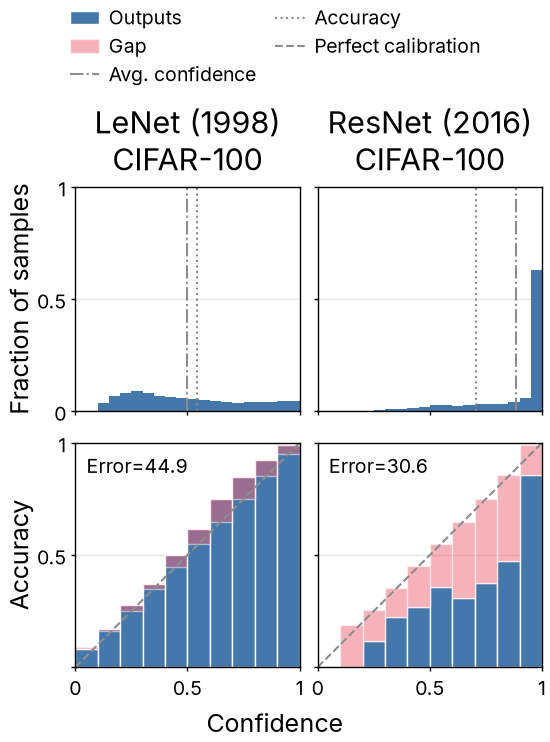

In [2]:
with open("../data/reliability-diagram.json") as f:
    data = json.load(f)
hist_edges = np.array(data["histogram_bin_edges"])
bin_edges = np.array(data["reliability_bin_edges"])

fig, axes = plt.subplots(2, 2, figsize=(2.75, 3), sharex="col", sharey="row")

for col, key in enumerate(["lenet", "resnet"]):
    m = data["models"][key]
    top, bottom = axes[0, col], axes[1, col]

    top.bar(hist_edges[:-1], m["fraction_of_samples_per_bin"], width=np.diff(hist_edges), align="edge",
            color=colors["series-1"], linewidth=0)
    top.axvline(m["avg_confidence_line"], linestyle="-.", linewidth=paper.dashed_width, color=colors["neutral"],
                label="Avg. confidence")
    top.axvline(m["accuracy_line"], linestyle=":", linewidth=paper.dashed_width, color=colors["neutral"],
                label="Accuracy")
    top.grid(axis="x", visible=False)
    top.set_title(f"{m['label']}\nCIFAR-100")

    accuracy = np.array(m["accuracy_per_bin"])
    confidence = np.array(m["avg_confidence_per_bin"])
    bottom.bar(bin_edges[:-1], accuracy, width=np.diff(bin_edges), align="edge",
               color=colors["series-1"], edgecolor="white", linewidth=0.5, label="Outputs")
    bottom.bar(bin_edges[:-1], confidence - accuracy, bottom=accuracy, width=np.diff(bin_edges), align="edge",
               color=colors["series-2"], alpha=0.5, edgecolor="white", linewidth=0.5, label="Gap")
    bottom.plot([0, 1], [0, 1], linestyle="--", linewidth=paper.dashed_width, color=colors["neutral"], zorder=1,
                label="Perfect calibration")
    bottom.grid(axis="x", visible=False)
    bottom.text(0.05, 0.95, f"Error={m['error_percent']}", transform=bottom.transAxes, ha="left", va="top",
                bbox=dict(facecolor="white", edgecolor="none", pad=1))

    for ax in (top, bottom):
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_xticks([0, 0.5, 1], labels=["0", "0.5", "1"])

axes[0, 0].set_yticks([0, 0.5, 1], labels=["0", "0.5", "1"])
axes[1, 0].set_yticks([0, 0.5, 1], labels=["", "0.5", "1"])
axes[0, 0].set_ylabel("Fraction of samples")
axes[1, 0].set_ylabel("Accuracy")
fig.supxlabel("Confidence")

bar_handles, bar_labels = axes[1, 0].get_legend_handles_labels()
line_handles, line_labels = axes[0, 0].get_legend_handles_labels()
fig.legend(bar_handles[1:] + line_handles + bar_handles[:1], bar_labels[1:] + line_labels + bar_labels[:1],
           loc="outside upper center", ncol=2, frameon=False, borderaxespad=0)

fit_height(fig, axes, aspect=1.0, min_width=1.0)
fig.savefig("../outputs/reliability-diagram.pdf")
fig.savefig("../outputs/reliability-diagram.png")
plt.show()